# Week 8: Exploring the Auto MPG Dataset

**Sebastian Perdomo | IS 362**

## 1. Load the data

`auto-mpg.data` has no header row and separates values with spaces. The column names
come from the attribute list in `auto-mpg.names`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

DATA_URL = "https://archive.ics.uci.edu/ml/machine-learning-databases/auto-mpg/auto-mpg.data"

columns = ["mpg", "cylinders", "displacement", "horsepower", "weight",
           "acceleration", "model_year", "origin", "car_name"]

cars = pd.read_csv(DATA_URL, sep=r"\s+", names=columns)
print(cars.shape)
cars.head()

(398, 9)


,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,car_name
0,18.0,8,307.0,130.0,3504.0,12.0,70,1,chevrolet chevelle malibu
1,15.0,8,350.0,165.0,3693.0,11.5,70,1,buick skylark 320
2,18.0,8,318.0,150.0,3436.0,11.0,70,1,plymouth satellite
3,16.0,8,304.0,150.0,3433.0,12.0,70,1,amc rebel sst
4,17.0,8,302.0,140.0,3449.0,10.5,70,1,ford torino


## 2. Review the data

The dataset has 398 cars from model years 1970 to 1982. Per the data set description,
mpg is city fuel economy, origin is a coded region, and car_name is unique to each car.

In [2]:
cars.dtypes

mpg             float64
cylinders         int64
displacement    float64
horsepower          str
weight          float64
acceleration    float64
model_year        int64
origin            int64
car_name            str
dtype: object

Horsepower should be a number, but pandas read it as text. That points to the missing
values marked with "?".

## 3. Fix the missing horsepower values

In [3]:
print("Rows marked '?':", (cars["horsepower"] == "?").sum())

cars["horsepower"] = pd.to_numeric(cars["horsepower"].replace("?", np.nan))

print("Missing after conversion:", cars["horsepower"].isna().sum())
print("Data type:", cars["horsepower"].dtype)

Rows marked '?': 6
Missing after conversion: 6
Data type: float64


## 4. Label the origin codes

In [4]:
make = cars["car_name"].str.split().str[0]
cars.assign(make=make).groupby("origin")["make"].agg(lambda m: ", ".join(m.value_counts().index[:5]))

origin
1     ford, chevrolet, plymouth, amc, dodge
2    volkswagen, peugeot, fiat, audi, volvo
3      toyota, datsun, honda, mazda, subaru
Name: make, dtype: str

Code 2 is Volkswagen, Peugeot, Fiat, Audi, and Volvo, which are European. Code 3 is
Toyota, Datsun, Honda, and Mazda, which are Asian.

In [5]:
cars["origin"] = cars["origin"].map({1: "USA", 2: "Europe", 3: "Asia"})
cars["origin"].value_counts()

origin
USA       249
Asia       79
Europe     70
Name: count, dtype: int64

## 5. Distribution of cylinders

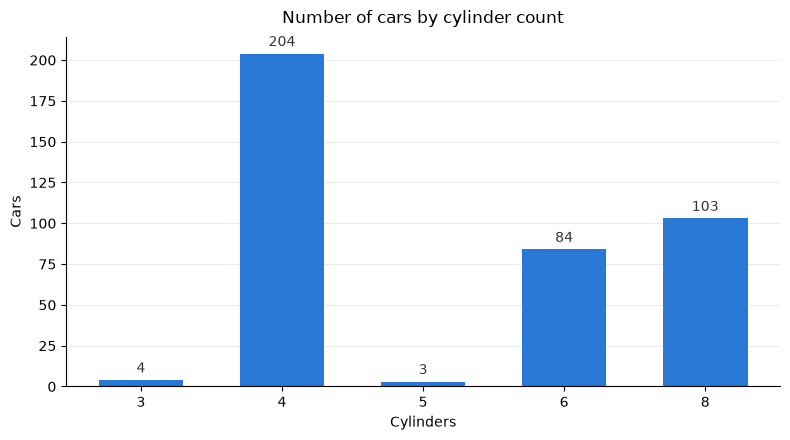

In [6]:
cyl_counts = cars["cylinders"].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.bar(cyl_counts.index.astype(str), cyl_counts.values, color="#2a78d6", width=0.6)
ax.bar_label(bars, padding=3, fontsize=10, color="#333333")
ax.set_title("Number of cars by cylinder count", fontsize=12, pad=10)
ax.set_xlabel("Cylinders")
ax.set_ylabel("Cars")
ax.grid(axis="y", alpha=0.3, linewidth=0.6)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

Most cars have 4, 6, or 8 cylinders, and 4 is the most common, at just over half. The
four 3-cylinder cars are all Mazda RX models, which use a rotary engine rather than
regular cylinders.

In [7]:
cars.loc[cars["cylinders"].isin([3, 5]), ["cylinders", "car_name"]]

,cylinders,car_name
71,3,mazda rx2 coupe
111,3,maxda rx3
243,3,mazda rx-4
274,5,audi 5000
297,5,mercedes benz 300d
327,5,audi 5000s (diesel)
334,3,mazda rx-7 gs


## 6. Horsepower and weight

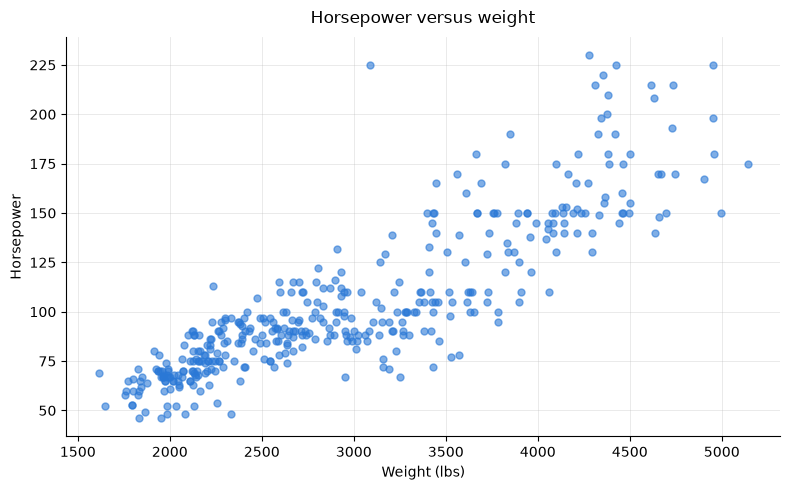

Correlation: 0.865


In [8]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(cars["weight"], cars["horsepower"], color="#2a78d6", alpha=0.6, s=25)
ax.set_title("Horsepower versus weight", fontsize=12, pad=10)
ax.set_xlabel("Weight (lbs)")
ax.set_ylabel("Horsepower")
ax.grid(alpha=0.3, linewidth=0.6)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

print("Correlation:", round(cars["horsepower"].corr(cars["weight"]), 3))

Heavier cars have more horsepower, and the relationship is strong and close to a
straight line.

## 7. Did American cars close the fuel-economy gap?

US cars in 1970 were known for poor fuel economy. Gas prices jumped during the 1970s,
so my question is whether American cars caught up with imports by 1982.

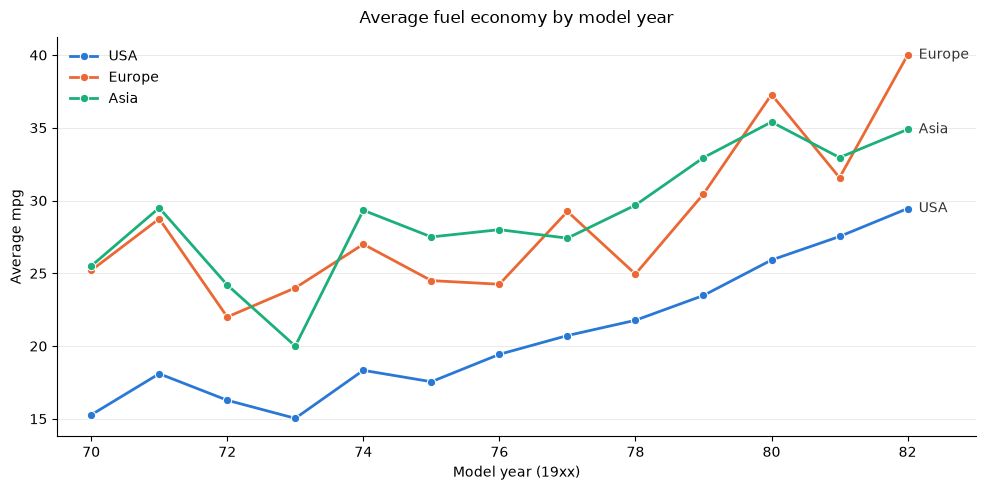

In [10]:
colors = {"USA": "#2a78d6", "Europe": "#eb6834", "Asia": "#1baf7a"}

yearly = cars.pivot_table(index="model_year", columns="origin", values="mpg", aggfunc="mean")

fig, ax = plt.subplots(figsize=(10, 5))
sns.lineplot(data=cars, x="model_year", y="mpg", hue="origin", palette=colors,
             hue_order=["USA", "Europe", "Asia"], errorbar=None, marker="o",
             linewidth=2, ax=ax)
for origin, color in colors.items():
    ax.annotate(origin, xy=(82, yearly.loc[82, origin]), xytext=(8, 0),
                textcoords="offset points", va="center", fontsize=10, color="#333333")
ax.set_title("Average fuel economy by model year", fontsize=12, pad=10)
ax.set_xlabel("Model year (19xx)")
ax.set_ylabel("Average mpg")
ax.set_xlim(69.5, 83)
ax.legend(title=None, frameon=False, loc="upper left")
ax.grid(axis="y", alpha=0.3, linewidth=0.6)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

Some years have only two to nine imported cars, so single-year averages jump around.
Comparing the first three model years with the last three gives a steadier picture.

In [11]:
early = cars[cars["model_year"] <= 72].groupby("origin")["mpg"].mean()
late = cars[cars["model_year"] >= 80].groupby("origin")["mpg"].mean()

summary = pd.DataFrame({"1970-72 mpg": early, "1980-82 mpg": late}).loc[["USA", "Europe", "Asia"]]
summary["Change"] = summary["1980-82 mpg"] - summary["1970-72 mpg"]
summary["Gap to USA"] = summary["1980-82 mpg"] - summary.loc["USA", "1980-82 mpg"]
summary.round(1)

,1970-72 mpg,1980-82 mpg,Change,Gap to USA
origin,,,,
USA,16.5,28.2,11.7,0.0
Europe,25.1,36.1,11.1,7.9
Asia,26.4,34.4,8.0,6.2


Weight helps explain why the gap stays.

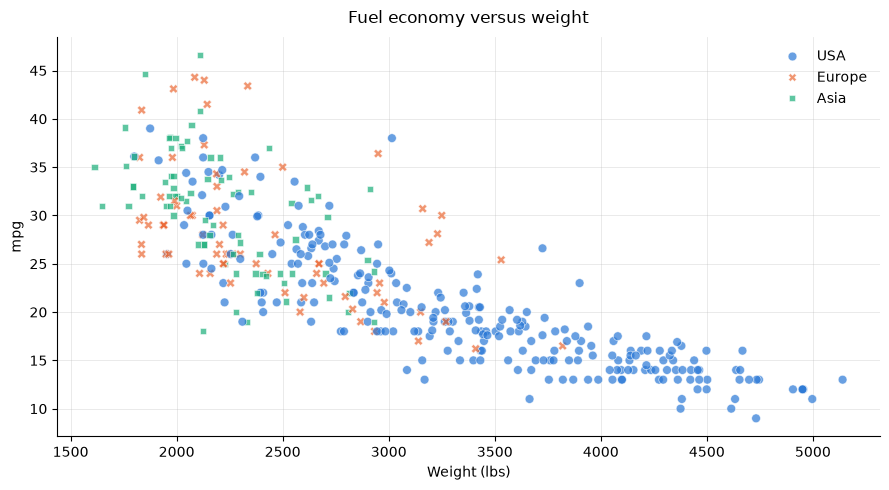

,weight,mpg
origin,,
USA,3362.0,20.0
Europe,2423.0,28.0
Asia,2221.0,30.0


In [12]:
fig, ax = plt.subplots(figsize=(9, 5))
sns.scatterplot(data=cars, x="weight", y="mpg", hue="origin", style="origin",
                palette=colors, hue_order=["USA", "Europe", "Asia"],
                style_order=["USA", "Europe", "Asia"], alpha=0.7, s=40, ax=ax)
ax.set_title("Fuel economy versus weight", fontsize=12, pad=10)
ax.set_xlabel("Weight (lbs)")
ax.set_ylabel("mpg")
ax.legend(title=None, frameon=False)
ax.grid(alpha=0.3, linewidth=0.6)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

cars.groupby("origin")[["weight", "mpg"]].mean().round(0).loc[["USA", "Europe", "Asia"]]

### Answer

Partly. American cars improved the most, from 16.5 mpg in 1970 to 1972 up to 28.2 mpg
in 1980 to 1982, a gain of 11.7 mpg. Their gap to Asian cars shrank from 9.9 mpg to
6.2, and their gap to European cars from 8.6 to 7.9. Even so, US cars had the lowest
average fuel economy in every model year.

Weight explains most of the gap. Fuel economy drops steadily as weight goes up, and US
cars averaged about 3,360 lbs against roughly 2,200 to 2,400 lbs for imports. In the
scatterplot, US cars and imports of the same weight get similar mileage, so where a car
was built matters less than how heavy it is.